# M2a: shared vs cell-type-specific calls

Contract: `audit/contracts/M2_shared_specific.md` (M2a). Logic: `src/m2a_calls.py` (tested in `tests/test_m2a.py`).
This notebook only reads `m2_calls.csv` and `m2_table.csv` and shows them.
Labels: `mixed` > `shared` / `shared*` > `partial` > `specific*` / `specific` (decisions O1, O2, specific* rule).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.m2a_calls import CELL_TYPES

pd.set_option("display.width", 160, "display.max_columns", 20)
PROC = ROOT / "data/processed"
calls = pd.read_csv(PROC / "m2_calls.csv")
table = pd.read_csv(PROC / "m2_table.csv")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## Outputs: shape, head, tail

In [2]:
for name, df in [("m2_calls.csv", calls), ("m2_table.csv", table)]:
    print(name, df.shape)
    display(df.head(), df.tail())

m2_calls.csv (125608, 9)


,cell_type,gene,log2FC,qvalue,ci_low,ci_high,tested,de,lodo_stable
0,B cells,7SK.2,-0.854989,NaN,-6.837130,5.127152,False,none,NaN
1,B cells,A1BG,-0.612272,0.64574,-1.860397,0.635854,True,none,NaN
2,B cells,A1BG-AS1,0.043555,NaN,-2.690890,2.778001,False,none,NaN
3,B cells,A2M,-0.378563,NaN,-6.373003,5.615876,False,none,NaN
4,B cells,A2M-AS1,NaN,NaN,NaN,NaN,False,none,NaN


,cell_type,gene,log2FC,qvalue,ci_low,ci_high,tested,de,lodo_stable
125603,NK cells,ZZEF1,0.223884,NaN,-3.195073,3.642842,False,none,NaN
125604,NK cells,ZZZ3,-0.792595,NaN,-2.935455,1.350265,False,none,NaN
125605,NK cells,hsa-mir-1199,-0.426780,NaN,-4.591667,3.738107,False,none,NaN
125606,NK cells,hsa-mir-335,-0.932546,NaN,-6.922016,5.056923,False,none,NaN
125607,NK cells,hsa-mir-8072,-0.180551,NaN,-3.089140,2.728037,False,none,NaN


m2_table.csv (2801, 13)


,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,Dendritic cells,Megakaryocytes,n_cell_types,shared_response,specific_star,megakaryocyte_lower_confidence
0,A1BG,–,↓,–,–,–,–,–,–,1,specific*,True,False
1,A4GALT,–,↓,–,–,–,–,–,–,1,specific,False,False
2,AAED1,–,↑,–,–,↑,–,–,–,2,partial,False,False
3,AAMDC,–,↑,–,–,–,–,–,–,1,specific*,True,False
4,AAMP,–,–,–,–,↓,–,–,–,1,specific*,True,False


,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,Dendritic cells,Megakaryocytes,n_cell_types,shared_response,specific_star,megakaryocyte_lower_confidence
2796,ZNRF2,–,↑,–,–,–,–,–,–,1,specific*,True,False
2797,ZRSR2,–,↑,–,–,–,↑,–,–,2,partial,False,False
2798,ZSCAN16,–,–,–,–,↑,–,–,–,1,specific*,True,False
2799,ZSWIM7,–,↓,–,–,↓,–,–,–,2,partial,False,False
2800,ZSWIM8,–,↓,–,–,–,–,–,–,1,specific*,True,False


## Label counts and number of responding cell types

In [3]:
ORDER = ["shared", "shared*", "partial", "specific", "specific*", "mixed"]
display(table["shared_response"].value_counts().reindex(ORDER).rename("genes").to_frame())
display(table["n_cell_types"].value_counts().sort_index().rename("genes").to_frame())
print("megakaryocyte_lower_confidence:", int(table["megakaryocyte_lower_confidence"].sum()), "genes")

,genes
shared_response,
shared,21
shared*,87
partial,856
specific,241
specific*,1585
mixed,11


,genes
n_cell_types,
1,1826
2,549
3,153
4,76
5,53
6,34
7,89
8,21


megakaryocyte_lower_confidence: 27 genes


## Table sorted by label, then number of cell types

In [4]:
sorted_table = table.assign(_o=table["shared_response"].map(ORDER.index)) \
    .sort_values(["_o", "n_cell_types", "gene"], ascending=[True, False, True]).drop(columns="_o")
display(sorted_table.head(30), sorted_table.tail(10))

,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,Dendritic cells,Megakaryocytes,n_cell_types,shared_response,specific_star,megakaryocyte_lower_confidence
487,CMPK2,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
756,EPSTI1,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
899,GBP1,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1026,HERC5,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1103,IFI44L,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1104,IFI6,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1106,IFIT1,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1107,IFIT2,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1108,IFIT3,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True
1112,IFITM3,↑,↑,↑,↑,↑,↑,↑,↑,8,shared,False,True


,gene,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,FCGR3A+ Monocytes,NK cells,Dendritic cells,Megakaryocytes,n_cell_types,shared_response,specific_star,megakaryocyte_lower_confidence
1185,ITGB2,–,↑,↓,–,–,↓,–,–,3,mixed,False,False
1531,NCF1,–,↑,↓,–,↑,–,–,–,3,mixed,False,False
2142,SCPEP1,–,↑,↓,–,↑,–,–,–,3,mixed,False,False
2574,TRIB1,↑,↓,–,–,↓,–,–,–,3,mixed,False,False
113,AOAH,–,↑,↓,–,–,–,–,–,2,mixed,False,False
358,CCL22,–,–,–,–,↑,–,↓,–,2,mixed,False,False
1156,INPP1,↑,↓,–,–,–,–,–,–,2,mixed,False,False
1303,LINC00996,–,↑,–,–,–,↓,–,–,2,mixed,False,False
1650,OPN3,–,–,↑,–,–,–,↓,–,2,mixed,False,False
2701,VPS37B,–,↓,–,–,–,↑,–,–,2,mixed,False,False


## Which cell-type combinations occur most (top 25 patterns, upset-style)
Each column of the dot matrix is one pattern (set of cell types where the gene is DE, either direction);
bar = number of genes with exactly that pattern.

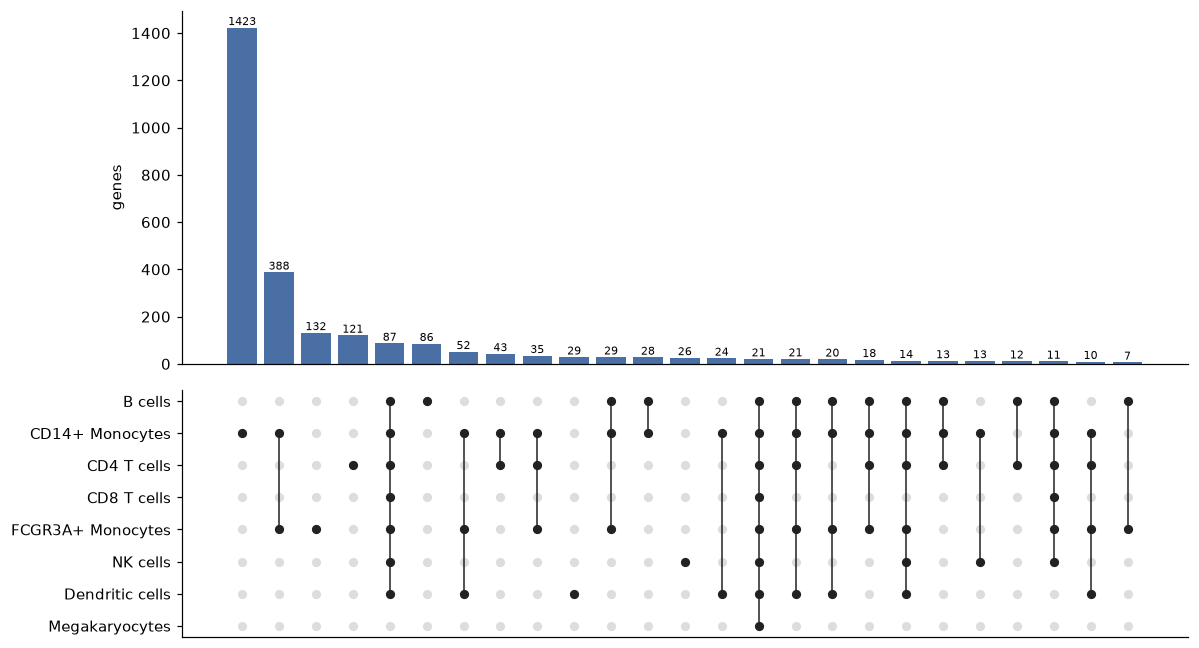

In [5]:
pattern = table[CELL_TYPES].ne("–")
counts = pattern.value_counts().head(25)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1.4]})
ax1.bar(range(len(counts)), counts.to_numpy(), color="#4a6fa5")
ax1.set_ylabel("genes")
for i, v in enumerate(counts.to_numpy()):
    ax1.text(i, v, str(v), ha="center", va="bottom", fontsize=7)
for i, combo in enumerate(counts.index):
    on = [j for j, x in enumerate(combo) if x]
    ax2.scatter([i] * len(CELL_TYPES), range(len(CELL_TYPES)), color="#dddddd", s=25)
    ax2.scatter([i] * len(on), on, color="#222222", s=25)
    ax2.plot([i, i], [min(on), max(on)], color="#222222", lw=1)
ax2.set_yticks(range(len(CELL_TYPES)), CELL_TYPES)
ax2.set_xticks([])
ax2.invert_yaxis()
plt.tight_layout()
plt.show()

## Direction heatmap (genes DE in ≥ 2 cell types, sorted by label and pattern)

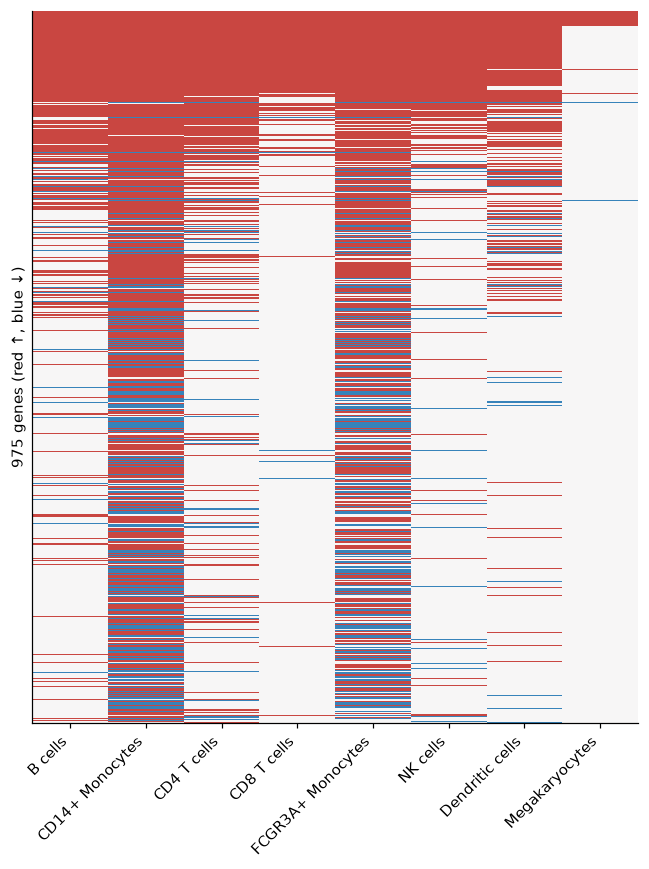

In [6]:
multi = sorted_table[sorted_table["n_cell_types"] >= 2]
val = multi[CELL_TYPES].apply(lambda col: col.map({"↑": 1, "↓": -1, "–": 0}))
fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(val.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-1.5, vmax=1.5, interpolation="nearest")
ax.set_xticks(range(len(CELL_TYPES)), CELL_TYPES, rotation=45, ha="right")
ax.set_yticks([])
ax.set_ylabel(f"{len(multi)} genes (red ↑, blue ↓)")
plt.tight_layout()
plt.show()

## LODO stability (R1): DE calls keeping their sign in every leave-one-donor-out refit

In [7]:
de_calls = calls[calls["de"] != "none"]
display(de_calls.groupby("cell_type")["lodo_stable"].agg(n_calls="size", stable="sum", pct=lambda s: 100 * s.mean()))
print(f"overall: {de_calls['lodo_stable'].sum()} / {len(de_calls)} = {100 * de_calls['lodo_stable'].mean():.1f}%")

,n_calls,stable,pct
cell_type,,,
B cells,433,433,100.0
CD14+ Monocytes,2335,2335,100.0
CD4 T cells,483,483,100.0
CD8 T cells,169,169,100.0
Dendritic cells,324,324,100.0
FCGR3A+ Monocytes,919,919,100.0
Megakaryocytes,27,27,100.0
NK cells,257,257,100.0


overall: 4947 / 4947 = 100.0%
